In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Check Runtime → Change runtime type.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:

from google.colab import files
import os
import shutil

os.makedirs("/content/data", exist_ok=True)

uploaded = files.upload()

for filename in ["train.parquet", "test.parquet"]:
    if filename in uploaded:
        shutil.move(filename, f"/content/data/{filename}")
    elif not os.path.exists(f"/content/data/{filename}"):
        raise FileNotFoundError(
            f"{filename} was not uploaded. Please upload both dataset files."
        )

print("Dataset files ready!")
print(os.listdir("/content/data"))


Saving test.parquet to test.parquet
Saving train.parquet to train.parquet
Dataset files ready!
['train.parquet', 'test.parquet']


In [3]:

!pip install -q pyarrow scikit-learn matplotlib pillow

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Libraries imported successfully!")


Device: cuda
Libraries imported successfully!


In [4]:

TRAIN_PATH = "/content/data/train.parquet"
TEST_PATH = "/content/data/test.parquet"

train_full_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

print("Training dataset shape:", train_full_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nColumns:")
print(train_full_df.columns.tolist())

print("\nTraining class distribution:")
print(train_full_df["label"].value_counts().sort_index())

print("\nFirst rows:")
display(train_full_df.head())


Training dataset shape: (5120, 2)
Testing dataset shape: (1280, 2)

Columns:
['image', 'label']

Training class distribution:
label
0     724
1      49
2    2566
3    1781
Name: count, dtype: int64

First rows:


,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,2
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,3
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,3
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,2


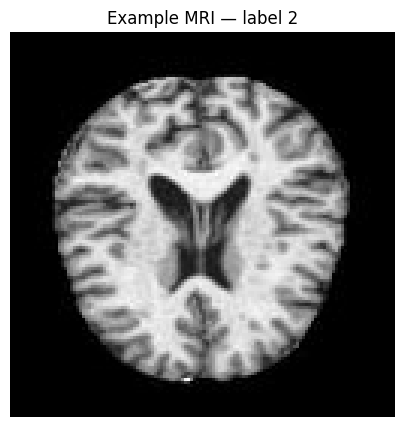

In [5]:

sample = train_full_df.iloc[0]
image_data = sample["image"]

if isinstance(image_data, dict):
    image_bytes = image_data["bytes"]
else:
    image_bytes = image_data

image = Image.open(BytesIO(image_bytes)).convert("L")

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title(f"Example MRI — label {sample['label']}")
plt.axis("off")
plt.show()


In [6]:

IMAGE_SIZE = 224
BATCH_SIZE = 32

train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.2,
    random_state=SEED,
    stratify=train_full_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))


class AlzheimerMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        sample = self.df.iloc[idx]
        image_data = sample["image"]

        if isinstance(image_data, dict):
            image_bytes = image_data["bytes"]
        else:
            image_bytes = image_data

        image = Image.open(BytesIO(image_bytes)).convert("L")
        label = int(sample["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229])
])


train_dataset = AlzheimerMRIDataset(train_df, train_transform)
val_dataset = AlzheimerMRIDataset(val_df, eval_transform)
test_dataset = AlzheimerMRIDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully!")


Training samples: 4096
Validation samples: 1024
Test samples: 1280
DataLoaders created successfully!


In [7]:

num_classes = int(train_full_df["label"].nunique())

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Adapt the first layer for grayscale images
old_conv = model.conv1

new_conv = nn.Conv2d(
    in_channels=1,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

with torch.no_grad():
    new_conv.weight.copy_(
        old_conv.weight.mean(dim=1, keepdim=True)
    )

model.conv1 = new_conv

# Replace the final layer
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Model: ResNet18")
print("Number of classes:", num_classes)
print("Training device:", device)
print("Model ready!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


Model: ResNet18
Number of classes: 4
Training device: cuda
Model ready!


In [8]:

def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            predictions = outputs.argmax(dim=1)

            all_preds.extend(predictions.detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy, all_preds, all_labels


EPOCHS = 5
best_val_acc = -1.0
best_model_path = "/content/best_resnet18.pth"

for epoch in range(EPOCHS):
    train_loss, train_acc, _, _ = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc, _, _ = run_epoch(
        model, val_loader, criterion
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

print("\nTraining completed!")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print("Saved model:", best_model_path)


Epoch [1/5] | Train Loss: 0.8987 | Train Accuracy: 0.6345 | Val Loss: 0.8219 | Val Accuracy: 0.6709
Epoch [2/5] | Train Loss: 0.5496 | Train Accuracy: 0.8352 | Val Loss: 0.5545 | Val Accuracy: 0.8350
Epoch [3/5] | Train Loss: 0.3729 | Train Accuracy: 0.9309 | Val Loss: 0.4889 | Val Accuracy: 0.8652
Epoch [4/5] | Train Loss: 0.3000 | Train Accuracy: 0.9675 | Val Loss: 0.4007 | Val Accuracy: 0.9199
Epoch [5/5] | Train Loss: 0.2664 | Train Accuracy: 0.9832 | Val Loss: 0.3468 | Val Accuracy: 0.9424

Training completed!
Best validation accuracy: 0.9424
Saved model: /content/best_resnet18.pth


In [9]:

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

test_loss, test_acc, test_preds, test_labels = run_epoch(
    model, test_loader, criterion
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_preds,
        zero_division=0
    )
)


Test Loss: 0.3559
Test Accuracy: 93.75%

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.88      0.90       172
           1       1.00      0.87      0.93        15
           2       0.95      0.97      0.96       634
           3       0.93      0.92      0.92       459

    accuracy                           0.94      1280
   macro avg       0.95      0.91      0.93      1280
weighted avg       0.94      0.94      0.94      1280



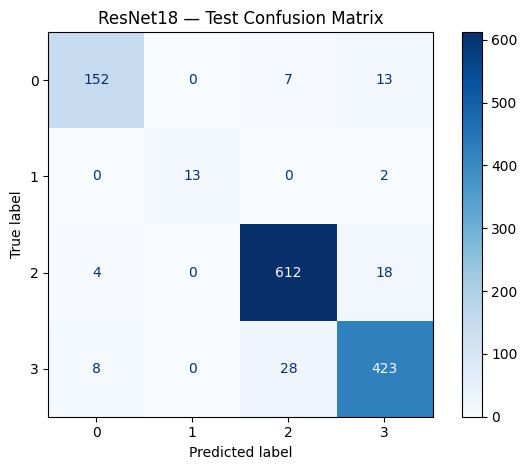

In [10]:

cm = confusion_matrix(test_labels, test_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(train_full_df["label"].unique())
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 — Test Confusion Matrix")
plt.tight_layout()
plt.show()


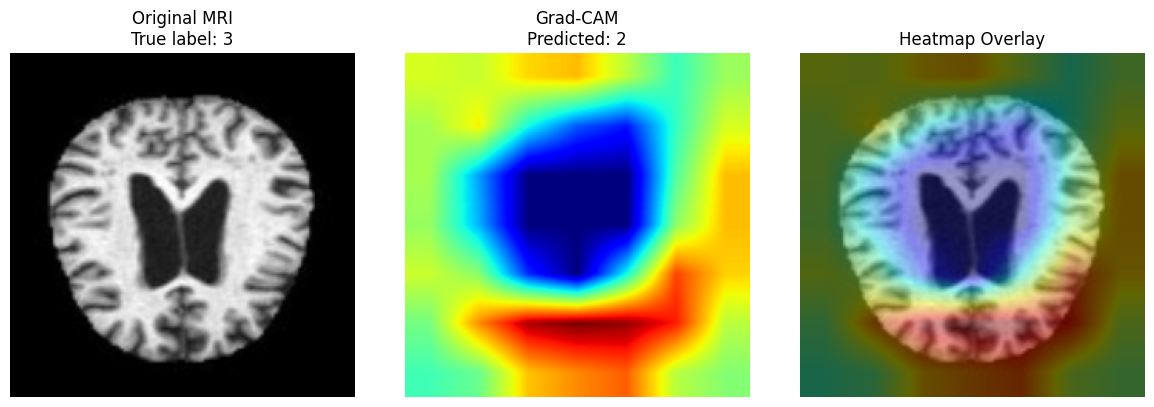

Saved: /content/gradcam_outputs/gradcam_1.png


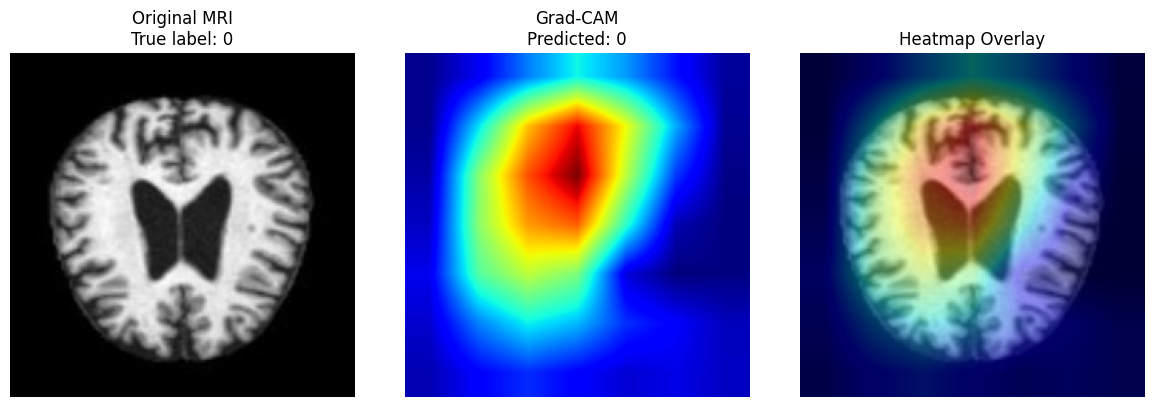

Saved: /content/gradcam_outputs/gradcam_2.png


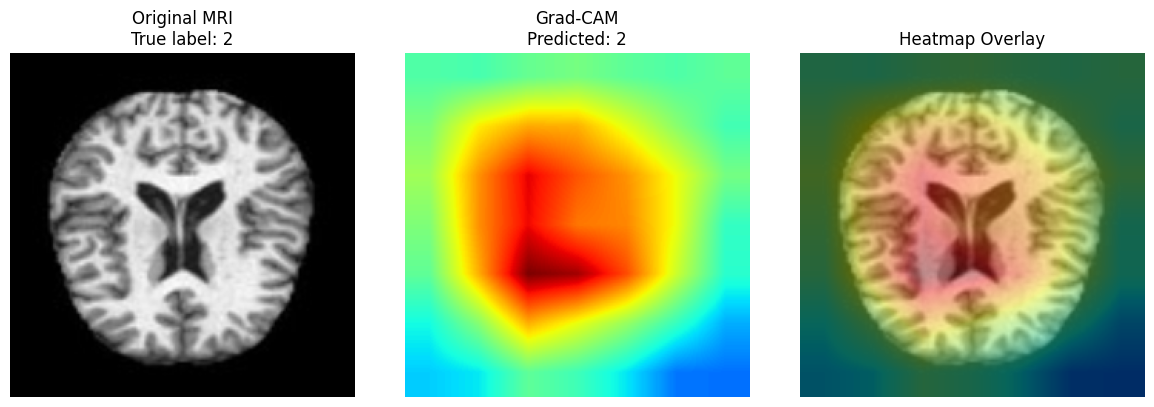

Saved: /content/gradcam_outputs/gradcam_3.png


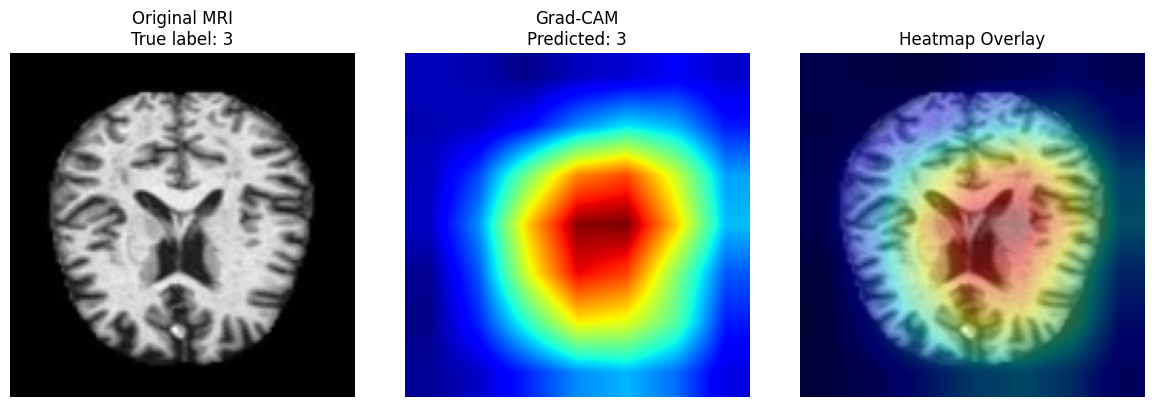

Saved: /content/gradcam_outputs/gradcam_4.png


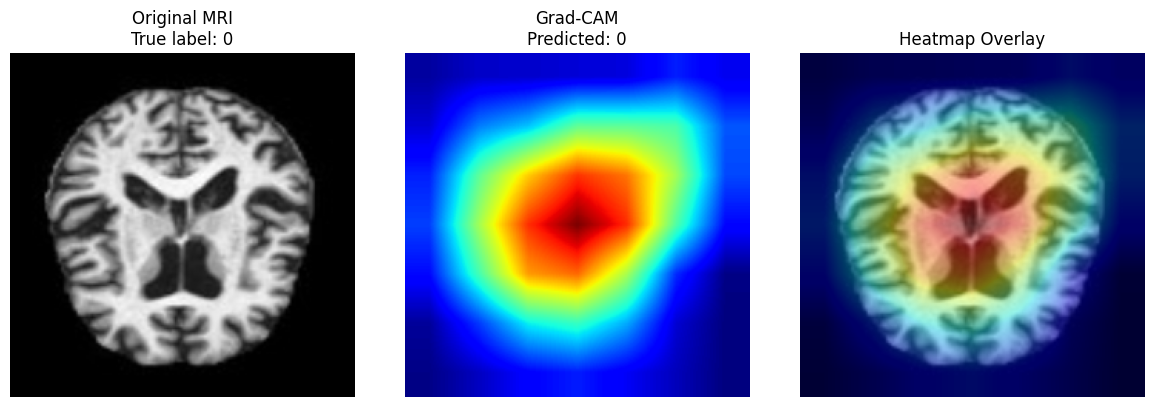

Saved: /content/gradcam_outputs/gradcam_5.png
Generated 5 Grad-CAM visualizations.


In [12]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.handle = target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, inputs, output):
        self.activations = output
        output.register_hook(self.save_gradient)

    def save_gradient(self, gradient):
        self.gradients = gradient

    def generate(self, input_tensor, class_idx):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)
        score = output[:, class_idx].sum()
        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam

    def close(self):
        self.handle.remove()


gradcam = GradCAM(model, model.layer4)

output_dir = "/content/gradcam_outputs"
os.makedirs(output_dir, exist_ok=True)

saved = 0
MAX_IMAGES = 5

for idx in range(len(test_dataset)):
    image_tensor, true_label = test_dataset[idx]
    input_tensor = image_tensor.unsqueeze(0).to(device)

    # Generate prediction and heatmap in a single gradient-enabled environment
    logits = model(input_tensor)
    predicted_label = int(logits.argmax(dim=1).item())

    heatmap = gradcam.generate(input_tensor, predicted_label)

    # Undo normalization for display
    original = image_tensor.squeeze().cpu().numpy()
    original = original * 0.229 + 0.485
    original = np.clip(original, 0, 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap="gray")
    plt.title(f"Original MRI\nTrue label: {true_label}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    plt.title(f"Grad-CAM\nPredicted: {predicted_label}")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original, cmap="gray")
    plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    plt.title("Heatmap Overlay")
    plt.axis("off")

    plt.tight_layout()

    save_path = f"{output_dir}/gradcam_{saved + 1}.png"
    plt.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", save_path)

    saved += 1
    if saved >= MAX_IMAGES:
        break

gradcam.close()
print(f"Generated {saved} Grad-CAM visualizations.")

In [13]:

from google.colab import files

files.download("/content/best_resnet18.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/gradcam_outputs",
    "zip",
    "/content/gradcam_outputs"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>